# Tarea I. Análisis Exploratorio de Datos

## Matrícula escolar por sede educativa en Colombia, 2024

**Fuente:** DANE, Microdatos de Educación Formal (EDUC) 2024. Categoría Sociedad, tema Educación.

**Integrantes:** Integrante 1, Integrante 2, Integrante 3

**Universidad Pedagógica y Tecnológica de Colombia (UPTC)**

**Herramientas:** R (readr, dplyr, tidyr, ggplot2) en un notebook de Jupyter con kernel R.

**Contenido**

1. Introducción: planteamiento del problema y objetivos
2. Descripción del conjunto de datos
3. Selección de variables
4. Limpieza de datos
5. Análisis exploratorio de datos
6. Conclusiones
7. Exportación a HTML

## 1. Introducción

### 1.1 Planteamiento del problema

La educación preescolar, básica y media en Colombia se presta en más de 55.000 sedes educativas, oficiales y no oficiales, ubicadas en zonas urbanas y rurales de los 33 departamentos. Estas sedes son muy distintas entre sí: una escuela rural puede atender a menos de 20 estudiantes, mientras que un colegio urbano puede superar los 5.000. Esa heterogeneidad hace que los promedios nacionales oculten la forma real en que se distribuyen los estudiantes y dificulta la planeación de recursos como docentes, infraestructura, alimentación escolar y conectividad.

El DANE publica cada año la operación estadística de Educación Formal (EDUC), que registra la matrícula de cada sede. Sin embargo, los microdatos no se pueden analizar directamente: incluyen sedes que no reportaron información, sedes inactivas, liquidadas o fusionadas y registros marcados como duplicados. Si no se depuran, las cifras por sede, por municipio y por departamento quedan sesgadas.

Por eso este trabajo plantea la siguiente pregunta: **¿cómo se distribuye la matrícula escolar entre las sedes educativas de Colombia en 2024 según el sector (oficial o no oficial) y la zona (urbana o rural), y qué municipios y departamentos concentran la mayor parte de los estudiantes?** Responderla permite dimensionar la concentración territorial de la demanda educativa y la diferencia de escala entre los tipos de sede, información útil para orientar la inversión pública y la oferta de programas de formación docente como los de la UPTC.

### 1.2 Objetivo general

Analizar la distribución de la matrícula escolar por sede educativa en Colombia en 2024, a partir de los microdatos de Educación Formal del DANE, para identificar las diferencias por sector y zona y los territorios con mayor concentración de estudiantes.

### 1.3 Objetivos específicos

1. Depurar los microdatos de Educación Formal 2024, cuantificando los datos perdidos y los registros duplicados y aplicando técnicas de exclusión e imputación justificadas.
2. Describir la matrícula total por sede con medidas de tendencia central, dispersión y forma, y comparar las sedes oficiales con las no oficiales y las urbanas con las rurales.
3. Identificar el Top 10 de municipios y de departamentos con mayor matrícula y calcular el porcentaje de la matrícula nacional que concentran.
4. Caracterizar el caso de Boyacá, identificando sus 10 municipios con mayor matrícula y el peso de los municipios donde la UPTC tiene sede.

## 2. Descripción del conjunto de datos

| Aspecto | Descripción |
|---|---|
| Operación estadística | Educación Formal (EDUC) 2024, DANE |
| Enlace | https://microdatos.dane.gov.co/index.php/catalog/906 |
| Categoría DANE | Sociedad, Educación |
| Cobertura | Nacional: 33 departamentos (incluye Bogotá D.C.) y 1.120 municipios |
| Universo | Sedes educativas oficiales y no oficiales de preescolar, básica, media y ciclos de adultos (CLEI) |
| Periodo de referencia | Año escolar 2024 (publicado por el DANE en abril de 2026) |
| Unidad de observación | Sede educativa, identificada con `SEDE_CODIGO` (12 dígitos) |
| Archivo descargado | `BDATOS-EDUC-2024.zip` (310 MB, 39 tablas en formato CSV y DTA) |

Del archivo comprimido se usan dos tablas en CSV, que se guardaron en la carpeta `datos/` con nombres sin espacios:

| Tabla original del DANE | Archivo en `datos/` | Contenido |
|---|---|---|
| Carátula única de la sede educativa | `caratula_sede_educativa_2024.csv` | Una fila por sede: ubicación (departamento y municipio), zona, sector, estado y novedad del reporte |
| Alumnos matriculados por jornadas y nivel educativo (educación tradicional, CLEI y modelos educativos) | `alumnos_matriculados_jornada_nivel_2024.csv` | Una fila por sede, jornada, nivel y modelo educativo, con el número de alumnos matriculados |

Las dos tablas se unen por `SEDE_CODIGO`.

In [1]:
suppressPackageStartupMessages({
  library(readr)
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(scales)
})

options(repr.plot.width = 11, repr.plot.height = 6, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png", dplyr.summarise.inform = FALSE,
        readr.show_col_types = FALSE, scipen = 999, cli.unicode = FALSE, width = 120)

azul <- "#2a78d6"
naranja <- "#eb6834"
gris <- "#a3a29c"
theme_set(theme_minimal(base_size = 13) +
            theme(panel.grid.minor = element_blank(),
                  plot.title = element_text(face = "bold"),
                  legend.position = "top"))

miles <- label_number(big.mark = ".", decimal.mark = ",")
porc <- function(v, d = 1) format(round(v, d), nsmall = d, decimal.mark = ",")

mostrar <- function(tabla, digitos = 2) {
  IRdisplay::display_html(paste(knitr::kable(
    tabla, format = "html", digits = digitos, row.names = FALSE,
    format.args = list(big.mark = ".", decimal.mark = ","),
    table.attr = 'class="dataframe"'), collapse = "\n"))
}

In [2]:
caratula <- read_csv("datos/caratula_sede_educativa_2024.csv",
                     col_types = cols(.default = col_character()))
matricula <- read_csv("datos/alumnos_matriculados_jornada_nivel_2024.csv",
                      col_types = cols(.default = col_character(),
                                       SEDEALUM_CANTIDAD = col_integer()))

mostrar(data.frame(
  tabla = c("Carátula de la sede", "Alumnos matriculados"),
  filas = c(nrow(caratula), nrow(matricula)),
  columnas = c(ncol(caratula), ncol(matricula)),
  sedes_distintas = c(n_distinct(caratula$SEDE_CODIGO), n_distinct(matricula$SEDE_CODIGO)),
  periodo = c(paste(unique(caratula$PERIODO_ANIO), collapse = ", "),
              paste(unique(matricula$PERIODO_ANIO), collapse = ", "))
))

tabla,filas,columnas,sedes_distintas,periodo
Carátula de la sede,55.748,76,55.748,2024
Alumnos matriculados,126.936,14,52.004,2024


**Análisis.** Las dos tablas corresponden al año 2024. La carátula tiene 55.748 filas y 55.748 códigos distintos, es decir, una fila por sede, con 76 columnas. La tabla de matrícula tiene 126.936 filas porque cada sede aparece una vez por cada combinación de jornada, nivel y modelo educativo; en ella solo hay 52.004 sedes distintas, así que 3.744 sedes de la carátula no tienen matrícula registrada.

In [3]:
mostrar(head(matricula %>% select(SEDE_CODIGO, JORNADA_NOMBRE, NIVELENSE_NOMBRE,
                                  MODELOEDUC_NOMBRE, SEDEALUM_CANTIDAD), 6))

mostrar(head(caratula %>% select(SEDE_CODIGO, SEDE_NOMBRE, CODIGOINTERNODEPTO, DEPTO,
                                 CODIGOINTERNOMUNI, MUNI, AREA_NOMBRE, SECTOR_NOMBRE,
                                 NOVEDAD_NOMBRE), 6))

SEDE_CODIGO,JORNADA_NOMBRE,NIVELENSE_NOMBRE,MODELOEDUC_NOMBRE,SEDEALUM_CANTIDAD
311001108129,Completa/Única (No oficiales),Preescolar,Escolarizado,72
281794001439,Única (Oficiales),Preescolar,Escolarizado,1
281794001439,Única (Oficiales),Básica primaria,Escuela nueva (entre 5 a 18 años),19
208549000037,Mañana,Básica secundaria,Posprimaria,28
244279001024,Mañana,Preescolar,Apoyo académico especial,2
244279001024,Mañana,Básica primaria,Educación tradicional,13


SEDE_CODIGO,SEDE_NOMBRE,CODIGOINTERNODEPTO,DEPTO,CODIGOINTERNOMUNI,MUNI,AREA_NOMBRE,SECTOR_NOMBRE,NOVEDAD_NOMBRE
266572000435,SEDE EDUCATIVO CIATOCITO,66,Risaralda,66572,Pueblo Rico,Rural,Oficial,Deuda
266572000907,INSTITUTO DOCENTE BEKE,66,Risaralda,66456,Mistrató,Rural,Oficial,Deuda
415759001686,ESCUELA QUEBRADA HONDA,15,Boyacá,15759,Sogamoso,Rural,Oficial,Deuda
252835001023,ACHOTAL RIO MIRA,52,Nariño,52835,San Andrés de Tumaco,Rural,Oficial,Deuda
252835001198,SEDE BAJO ZAPOTAL,52,Nariño,52835,San Andrés de Tumaco,Rural,Oficial,Deuda
252835001201,VUELTA DE CANDELILLAS,52,Nariño,52835,San Andrés de Tumaco,Rural,Oficial,Deuda


**Análisis.** La tabla de matrícula está en formato largo: la misma sede (por ejemplo `281794001439`) aparece en varias filas, una por nivel y modelo, así que para tener un solo valor por sede hay que sumar `SEDEALUM_CANTIDAD`. En la carátula están las variables geográficas con sus códigos DIVIPOLA (departamento de 2 dígitos y municipio de 5), la zona, el sector y la novedad. Las primeras filas son sedes en `Deuda`, que son justamente las que no entregaron información.

## 3. Selección de variables

| Variable | Tipo | Origen | Descripción |
|---|---|---|---|
| `matricula_total` | Cuantitativa discreta | Suma de `SEDEALUM_CANTIDAD` por sede | Total de alumnos matriculados en la sede en 2024 (todas las jornadas, niveles y modelos) |
| `sector` | Cualitativa nominal | `SECTOR_NOMBRE` | Oficial o No Oficial |
| `zona` | Cualitativa nominal | `AREA_NOMBRE` | Urbana o Rural (variable cualitativa complementaria) |
| `cod_depto`, `departamento` | Código geográfico | `CODIGOINTERNODEPTO`, `DEPTO` | Código DIVIPOLA de 2 dígitos y nombre del departamento |
| `cod_muni`, `municipio` | Código geográfico | `CODIGOINTERNOMUNI`, `MUNI` | Código DIVIPOLA de 5 dígitos y nombre del municipio |
| `novedad` | Cualitativa (control) | `NOVEDAD_NOMBRE` | Situación del reporte de la sede; se usa en la limpieza |
| `sede_nombre`, `direccion` | Texto (control) | `SEDE_NOMBRE`, `SEDE_DIRECCION` | Se usan para detectar sedes repetidas |

La variable cuantitativa se construye sumando la matrícula de cada sede en la tabla de alumnos y se une a la carátula con un `left_join`, para conservar también las sedes que no tienen matrícula reportada.

In [4]:
totales <- matricula %>%
  group_by(SEDE_CODIGO) %>%
  summarise(matricula_total = sum(SEDEALUM_CANTIDAD))

sedes <- caratula %>%
  transmute(sede_codigo = SEDE_CODIGO, sede_nombre = SEDE_NOMBRE, direccion = SEDE_DIRECCION,
            cod_depto = CODIGOINTERNODEPTO, departamento = DEPTO,
            cod_muni = CODIGOINTERNOMUNI, municipio = MUNI,
            sector = SECTOR_NOMBRE, zona = AREA_NOMBRE, novedad = NOVEDAD_NOMBRE) %>%
  left_join(totales, by = c("sede_codigo" = "SEDE_CODIGO"))

cat("Sedes en la base:", nrow(sedes), "| Variables:", ncol(sedes), "\n")
cat("Sedes con matrícula reportada:", sum(!is.na(sedes$matricula_total)), "\n")
cat("Sedes de la tabla de matrícula sin carátula:", sum(!totales$SEDE_CODIGO %in% caratula$SEDE_CODIGO), "\n")
cat("Departamentos:", n_distinct(sedes$cod_depto), "| Municipios:", n_distinct(sedes$cod_muni), "\n")

Sedes en la base: 55748 | Variables: 11 


Sedes con matrícula reportada: 52004 


Sedes de la tabla de matrícula sin carátula: 0 


Departamentos: 33 | Municipios: 1120 


**Análisis.** La base de análisis queda con una fila por sede (55.748) y 11 variables. Todas las sedes de la tabla de matrícula existen en la carátula, así que la unión no pierde información. La cobertura es completa: 33 departamentos y 1.120 municipios. De las 55.748 sedes, 52.004 tienen matrícula reportada y las demás quedan con `matricula_total` nulo.

## 4. Limpieza de datos

### 4.1 Identificación de datos perdidos

In [5]:
nulos <- sapply(sedes, function(x) sum(is.na(x)))
mostrar(data.frame(variable = names(nulos), nulos = nulos,
                   porcentaje = round(nulos / nrow(sedes) * 100, 2)))

nulos_caratula <- sapply(caratula, function(x) sum(is.na(x)))
cat("Columnas de la carátula original con algún nulo:", sum(nulos_caratula > 0), "de", ncol(caratula), "\n")

variable,nulos,porcentaje
sede_codigo,0,"0,00"
sede_nombre,0,"0,00"
direccion,0,"0,00"
cod_depto,0,"0,00"
departamento,0,"0,00"
cod_muni,0,"0,00"
municipio,0,"0,00"
sector,0,"0,00"
zona,0,"0,00"
novedad,0,"0,00"


Columnas de la carátula original con algún nulo: 44 de 76 


**Análisis.** El único campo con datos perdidos es `matricula_total`, con 3.744 nulos (6,72 % de las sedes). Las variables geográficas, el sector y la zona están completas. En la carátula original 44 de las 76 columnas tienen nulos, pero son campos que no se usan en este análisis (contacto, convenios, bilingüismo, resguardo indígena, entre otros).

In [6]:
mostrar(sedes %>%
  group_by(novedad) %>%
  summarise(sedes = n(), sin_matricula = sum(is.na(matricula_total))) %>%
  arrange(desc(sedes)))

novedad,sedes,sin_matricula
Rinde,51.413,0
Inactiva,1.741,1.741
Deuda,1.407,1.407
Imputada,591,0
Liquidada,474,474
Duplicada,102,102
Fusionada,18,18
No pertenece al universo de la investigación,2,2


**Análisis.** Los nulos no son aleatorios: dependen de la novedad de la sede. Las sedes que rindieron informe (51.413) y las que el DANE ya imputó (591) tienen matrícula completa. Todos los nulos están en sedes Inactivas (1.741), en Deuda (1.407), Liquidadas (474), Duplicadas (102), Fusionadas (18) o fuera del universo (2). Esto define el tratamiento: las sedes que no funcionaron se excluyen y solo las sedes en Deuda, que siguen activas pero no reportaron, se imputan.

### 4.2 Datos repetidos

Se revisan los duplicados antes de imputar, para no imputar valores sobre registros repetidos.

In [7]:
cat("Filas repetidas en la carátula:", sum(duplicated(caratula)), "\n")
cat("Filas repetidas en la tabla de matrícula:", sum(duplicated(matricula)), "\n")
cat("Códigos de sede repetidos en la carátula:", sum(duplicated(caratula$SEDE_CODIGO)), "\n")
cat("Combinaciones sede, jornada, nivel y modelo repetidas:",
    sum(duplicated(matricula[, c("SEDE_CODIGO", "JORNADA_ID", "NIVELENSE_ID", "MODELOEDUC_ID")])), "\n")

antes <- nrow(sedes)
sedes <- distinct(sedes)
cat("Filas eliminadas con distinct():", antes - nrow(sedes), "\n")

Filas repetidas en la carátula: 0 


Filas repetidas en la tabla de matrícula: 0 


Códigos de sede repetidos en la carátula: 0 


Combinaciones sede, jornada, nivel y modelo repetidas: 0 


Filas eliminadas con distinct(): 0 


**Análisis.** No hay filas idénticas en ninguna de las dos tablas, ni códigos de sede repetidos en la carátula, ni combinaciones de sede, jornada, nivel y modelo repetidas en la matrícula; por eso `distinct()` no elimina filas. Esto garantiza que cada código aparece una sola vez, pero no descarta que una misma sede esté registrada con dos códigos distintos, lo que se revisa a continuación.

In [8]:
antes <- nrow(sedes)
sedes <- sedes %>% filter(novedad != "Duplicada")
cat("Antes:", antes, "| Después:", nrow(sedes), "| Eliminadas:", antes - nrow(sedes), "\n")

Antes: 55748 | Después: 55646 | Eliminadas: 102 


**Análisis.** El DANE marca 102 sedes con la novedad Duplicada, es decir, registros que repiten otra sede existente. Ninguna tiene matrícula y se eliminan para no contarlas dos veces. La base pasa de 55.748 a 55.646 sedes.

In [9]:
en_operacion <- c("Rinde", "Imputada", "Deuda")

repetidas <- sedes %>%
  filter(novedad %in% en_operacion) %>%
  group_by(sede_nombre, cod_muni, direccion) %>%
  filter(n() > 1) %>%
  arrange(is.na(matricula_total), .by_group = TRUE) %>%
  mutate(sobra = row_number() > 1 & is.na(matricula_total)) %>%
  ungroup()

mostrar(repetidas %>% select(sede_codigo, sede_nombre, municipio, novedad, matricula_total, sobra))

antes <- nrow(sedes)
sedes <- sedes %>% filter(!sede_codigo %in% repetidas$sede_codigo[repetidas$sobra])
cat("Antes:", antes, "| Después:", nrow(sedes), "| Eliminadas:", antes - nrow(sedes), "\n")

sede_codigo,sede_nombre,municipio,novedad,matricula_total,sobra
111001094480,BRASILIA BOSA,"Bogotá, D.C.",Rinde,571,FALSE
111001014109,BRASILIA BOSA,"Bogotá, D.C.",Rinde,1.858,FALSE
252699000573,CENTRO EDUCATIVO LA LIBERTAD,Ricaurte,Rinde,35,FALSE
252612000573,CENTRO EDUCATIVO LA LIBERTAD,Ricaurte,Rinde,34,FALSE
111001045322,COLEGIO COLOMBIA VIVA INSTITUCIÓN EDUCATIVA DISTRITAL,"Bogotá, D.C.",Imputada,1.392,FALSE
111001102091,COLEGIO COLOMBIA VIVA INSTITUCIÓN EDUCATIVA DISTRITAL,"Bogotá, D.C.",Rinde,1.433,FALSE
223001001182,ESCUELA RURAL MIXTA EL TOTUMO,Montería,Rinde,17,FALSE
223001800167,ESCUELA RURAL MIXTA EL TOTUMO,Montería,Rinde,12,FALSE
286001000463,ESCUELA RURAL MIXTA LA PEDREGOSA,Puerto Guzmán,Rinde,15,FALSE
286001002776,ESCUELA RURAL MIXTA LA PEDREGOSA,Puerto Guzmán,Rinde,1,FALSE


Antes: 55646 | Después: 55643 | Eliminadas: 3 


**Análisis.** Entre las sedes activas hay 12 pares con el mismo nombre, municipio y dirección pero distinto código. En 9 pares las dos sedes reportaron matrículas diferentes (por ejemplo Brasilia Bosa, con 571 y 1.858 alumnos), lo que indica sedes distintas que comparten edificio, así que se conservan. En los otros 3 casos el registro sobrante no tiene matrícula y está en Deuda: en dos de ellos la misma sede ya reportó con otro código y en el tercero (Sede La Laguna, en Cácota) las dos copias están en Deuda, así que se deja una. Si no se eliminaran, la imputación contaría dos veces la misma sede. Quedan 55.643 sedes.

### 4.3 Tratamiento de datos perdidos

Los nulos de `matricula_total` tienen dos orígenes distintos y por eso se tratan con técnicas diferentes:

* **Exclusión:** las sedes inactivas, liquidadas, fusionadas o fuera del universo no funcionaron en 2024. Su nulo no es un dato faltante sino una sede sin estudiantes, así que se excluyen.
* **Imputación:** las sedes en `Deuda` siguen activas pero no entregaron el formulario. Excluirlas subestimaría la matrícula de su municipio, así que se imputan con la **mediana** de sedes comparables. Se usa la mediana y no la media porque la distribución es muy asimétrica (sección 5.1).

In [10]:
antes <- nrow(sedes)
sedes <- sedes %>% filter(novedad %in% en_operacion)
cat("Antes:", antes, "| Después:", nrow(sedes), "| Excluidas:", antes - nrow(sedes), "\n")
cat("Nulos restantes en matricula_total:", sum(is.na(sedes$matricula_total)), "\n")

Antes: 55643 | Después: 53408 | Excluidas: 2235 


Nulos restantes en matricula_total: 1404 


**Análisis.** Se excluyen 2.235 sedes que no funcionaron en 2024: 1.741 inactivas, 474 liquidadas, 18 fusionadas y 2 fuera del universo. Su nulo no es un dato faltante, porque no tenían alumnos que reportar. Quedan 53.408 sedes y 1.404 nulos, todos de sedes en Deuda.

In [11]:
reportadas <- sedes %>% filter(!is.na(matricula_total))

med_muni <- reportadas %>% group_by(cod_muni, sector, zona) %>%
  summarise(med_muni = round(median(matricula_total)))
med_depto <- reportadas %>% group_by(cod_depto, sector, zona) %>%
  summarise(med_depto = round(median(matricula_total)))
med_nal <- reportadas %>% group_by(sector, zona) %>%
  summarise(med_nal = round(median(matricula_total)))

sedes <- sedes %>%
  left_join(med_muni, by = c("cod_muni", "sector", "zona")) %>%
  left_join(med_depto, by = c("cod_depto", "sector", "zona")) %>%
  left_join(med_nal, by = c("sector", "zona")) %>%
  mutate(origen = case_when(!is.na(matricula_total) ~ "Reportada",
                            !is.na(med_muni) ~ "Imputada: municipio",
                            !is.na(med_depto) ~ "Imputada: departamento",
                            TRUE ~ "Imputada: nacional"),
         matricula_total = coalesce(matricula_total, med_muni, med_depto, med_nal),
         sector = factor(sector, levels = c("Oficial", "No Oficial"))) %>%
  select(-med_muni, -med_depto, -med_nal)

mostrar(sedes %>% group_by(origen) %>%
  summarise(sedes = n(), matricula = sum(matricula_total), mediana = median(matricula_total)) %>%
  mutate(porc_matricula = round(matricula / sum(matricula) * 100, 2)))

origen,sedes,matricula,mediana,porc_matricula
Imputada: departamento,38,2.405,55,"0,03"
Imputada: municipio,1.366,138.459,41,"1,46"
Reportada,52.004,9.328.665,39,"98,51"


**Análisis.** Se imputaron 1.404 sedes: 1.366 con la mediana de su mismo municipio, sector y zona, y 38 con la de su departamento, porque en su municipio no había sedes comparables con datos; no fue necesario usar la mediana nacional. Las sedes imputadas suman 140.864 alumnos, solo el 1,49 % de la matrícula final, y su mediana (41 a 55 alumnos) es parecida a la de las sedes que reportaron (39), así que la imputación no cambia la forma de la distribución.

In [12]:
cat("Sedes en la base limpia:", nrow(sedes), "\n")
cat("Nulos totales:", sum(is.na(sedes)), "| Filas repetidas:", sum(duplicated(sedes)),
    "| Códigos repetidos:", sum(duplicated(sedes$sede_codigo)), "\n")
cat("Matrícula total:", format(sum(sedes$matricula_total), big.mark = ".", decimal.mark = ","), "estudiantes\n")

write_csv(sedes, "datos/sedes_educativas_2024_limpio.csv")

Sedes en la base limpia: 53408 


Nulos totales: 0 | Filas repetidas: 0 | Códigos repetidos: 0 


Matrícula total: 9.469.529 estudiantes


**Análisis.** La base limpia tiene 53.408 sedes, sin nulos ni registros repetidos, y una matrícula total de 9.469.529 estudiantes. Se guarda en `datos/sedes_educativas_2024_limpio.csv` para poder reutilizarla sin repetir la limpieza.

## 5. Análisis exploratorio de datos

### 5.1 Medidas descriptivas de la variable cuantitativa

In [13]:
moda <- function(x) {
  frecuencias <- table(x)
  as.numeric(names(frecuencias)[which.max(frecuencias)])
}
asimetria <- function(x) mean((x - mean(x))^3) / sd(x)^3
curtosis <- function(x) mean((x - mean(x))^4) / sd(x)^4 - 3

x <- sedes$matricula_total
limite <- quantile(x, 0.75) + 1.5 * IQR(x)
medidas <- data.frame(
  medida = c("Número de sedes", "Media", "Mediana", "Moda", "Desviación estándar", "Varianza",
             "Coeficiente de variación (%)", "Mínimo", "Primer cuartil (Q1)", "Tercer cuartil (Q3)",
             "Máximo", "Rango", "Rango intercuartílico (RIC)", "Límite de atípicos (Q3 + 1,5 RIC)",
             "Sedes por encima del límite", "Percentil 90", "Percentil 99",
             "Asimetría", "Curtosis (exceso)"),
  valor = c(length(x), mean(x), median(x), moda(x), sd(x), var(x), sd(x) / mean(x) * 100,
            min(x), quantile(x, 0.25), quantile(x, 0.75), max(x), max(x) - min(x), IQR(x),
            limite, sum(x > limite), quantile(x, 0.90), quantile(x, 0.99), asimetria(x), curtosis(x))
)
decimales <- c(0, 2, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2)
medidas$valor <- mapply(function(v, d) formatC(v, format = "f", digits = d, big.mark = ".",
                                               decimal.mark = ","), medidas$valor, decimales)
mostrar(medidas)
cat("Porcentaje de sedes por encima del límite de atípicos:", porc(mean(x > limite) * 100), "%\n")

medida,valor
Número de sedes,53.408
Media,"177,31"
Mediana,39
Moda,10
Desviación estándar,"339,68"
Varianza,"115.382,09"
Coeficiente de variación (%),"191,58"
Mínimo,1
Primer cuartil (Q1),13
Tercer cuartil (Q3),179


Porcentaje de sedes por encima del límite de atípicos: 12,0 %


**Análisis.** La matrícula por sede es muy asimétrica a la derecha. La media (177,3 alumnos) es 4,5 veces la mediana (39) y la moda es apenas 10 alumnos, porque la mayoría de las sedes son escuelas pequeñas. La mitad central de las sedes tiene entre 13 y 179 alumnos, pero el máximo llega a 6.558. La desviación estándar (339,7) casi duplica la media (coeficiente de variación de 191,6 %), la asimetría es 4,05 y la curtosis 25,2, lo que confirma una cola larga de sedes muy grandes: el 10 % de las sedes supera los 506 alumnos y el 1 % los 1.643. Con la regla del rango intercuartílico, 6.432 sedes (12,0 %) quedan por encima de 428 alumnos; no son errores sino colegios grandes, por eso se conservan. La mediana describe mejor la sede típica que la media.

In [14]:
resumen_grupo <- function(datos, grupo) {
  datos %>%
    group_by({{ grupo }}) %>%
    summarise(sedes = n(), matricula = sum(matricula_total), media = mean(matricula_total),
              mediana = median(matricula_total), desv_est = sd(matricula_total),
              q1 = quantile(matricula_total, 0.25), q3 = quantile(matricula_total, 0.75),
              maximo = max(matricula_total)) %>%
    mutate(porc_sedes = sedes / sum(sedes) * 100, porc_matricula = matricula / sum(matricula) * 100)
}

mostrar(resumen_grupo(sedes, sector), 1)
mostrar(resumen_grupo(sedes, zona), 1)

sector,sedes,matricula,media,mediana,desv_est,q1,q3,maximo,porc_sedes,porc_matricula
Oficial,43.786,7.339.841,"167,6","27,0","346,1",11,150,5.727,82,"77,5"
No Oficial,9.622,2.129.688,"221,3","124,5","305,1",58,262,6.558,18,"22,5"


zona,sedes,matricula,media,mediana,desv_est,q1,q3,maximo,porc_sedes,porc_matricula
Rural,35.951,2.277.883,"63,4",19,"134,8",10,50,3.061,"67,3","24,1"
Urbana,17.457,7.191.646,"412,0",233,"483,5",102,541,6.558,"32,7","75,9"


**Análisis.** Las sedes oficiales son el 82 % del total y atienden el 77,5 % de la matrícula. Su mediana (27 alumnos) es mucho menor que la de las no oficiales (124,5), aunque su media es más cercana (167,6 frente a 221,3) porque entre las oficiales hay colegios muy grandes. Por zona la diferencia es mayor: las sedes rurales son el 67,3 % pero tienen solo el 24,1 % de la matrícula, con una mediana de 19 alumnos frente a 233 en las urbanas. El tamaño de la sede depende más de la zona que del sector.

### 5.2 Gráficos

Sedes con menos de 100 alumnos: 34671 (64,9 %) 


Sedes con más de 2.000 alumnos: 263 (0,49 %) 


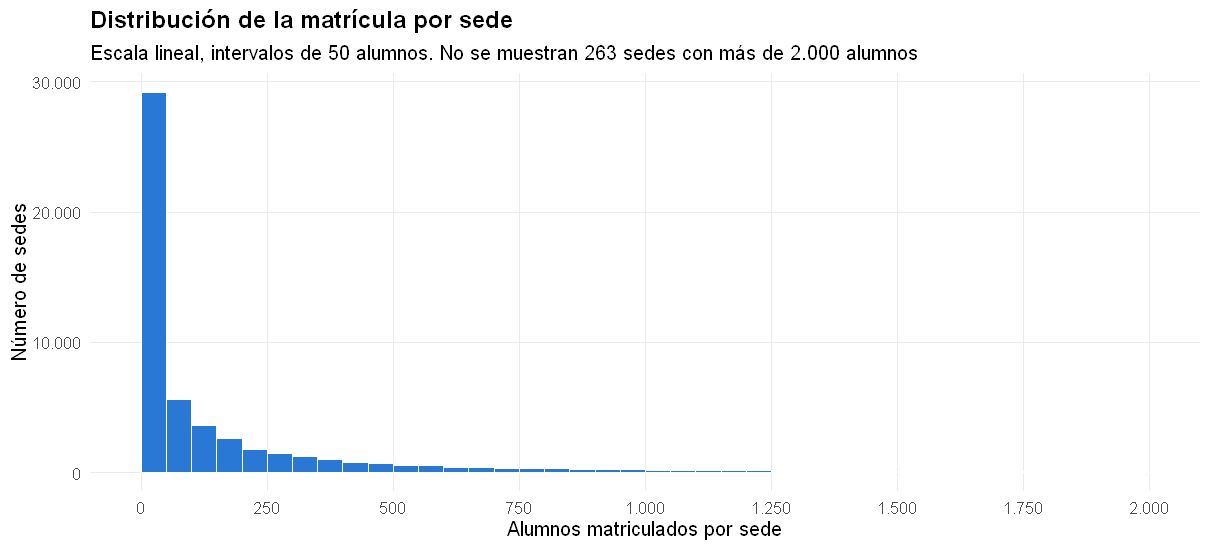

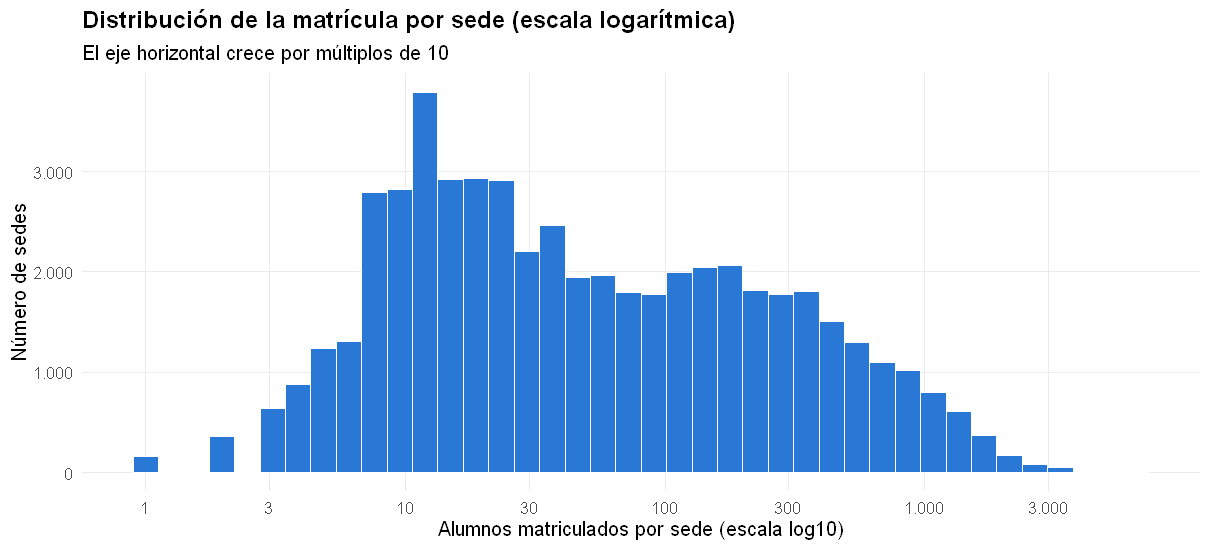

In [15]:
options(repr.plot.width = 11, repr.plot.height = 5)

mayores_2000 <- sum(sedes$matricula_total > 2000)
cat("Sedes con menos de 100 alumnos:", sum(sedes$matricula_total < 100),
    paste0("(", porc(mean(sedes$matricula_total < 100) * 100), " %)"), "\n")
cat("Sedes con más de 2.000 alumnos:", mayores_2000,
    paste0("(", porc(mean(sedes$matricula_total > 2000) * 100, 2), " %)"), "\n")

ggplot(sedes, aes(matricula_total)) +
  geom_histogram(binwidth = 50, boundary = 0, fill = azul, color = "white", linewidth = 0.2) +
  coord_cartesian(xlim = c(0, 2000)) +
  scale_x_continuous(labels = miles, breaks = seq(0, 2000, 250)) +
  scale_y_continuous(labels = miles) +
  labs(title = "Distribución de la matrícula por sede",
       subtitle = paste0("Escala lineal, intervalos de 50 alumnos. No se muestran ", mayores_2000,
                         " sedes con más de 2.000 alumnos"),
       x = "Alumnos matriculados por sede", y = "Número de sedes")

ggplot(sedes, aes(matricula_total)) +
  geom_histogram(bins = 40, fill = azul, color = "white", linewidth = 0.2) +
  scale_x_log10(labels = miles, breaks = c(1, 3, 10, 30, 100, 300, 1000, 3000)) +
  scale_y_continuous(labels = miles) +
  labs(title = "Distribución de la matrícula por sede (escala logarítmica)",
       subtitle = "El eje horizontal crece por múltiplos de 10",
       x = "Alumnos matriculados por sede (escala log10)", y = "Número de sedes")

**Análisis.** En escala lineal la distribución es una curva en forma de L: 34.671 sedes (64,9 %) tienen menos de 100 alumnos y la frecuencia cae rápidamente a medida que aumenta la matrícula; solo 263 sedes (0,49 %) superan los 2.000 alumnos. En escala logarítmica aparece una forma que la escala lineal oculta: un pico entre 8 y 30 alumnos, que corresponde a las escuelas rurales pequeñas, y una segunda zona amplia entre 100 y 1.000 alumnos, propia de los colegios urbanos. Hay dos tipos de sede muy distintos, y resumirlos con un solo promedio es engañoso.

zona,sector,sedes,mediana,q1,q3,media
Rural,Oficial,35.258,18,10,47,"60,4"
Rural,No Oficial,693,125,50,270,"214,1"
Urbana,Oficial,8.528,435,217,852,"611,0"
Urbana,No Oficial,8.929,124,58,262,"221,9"


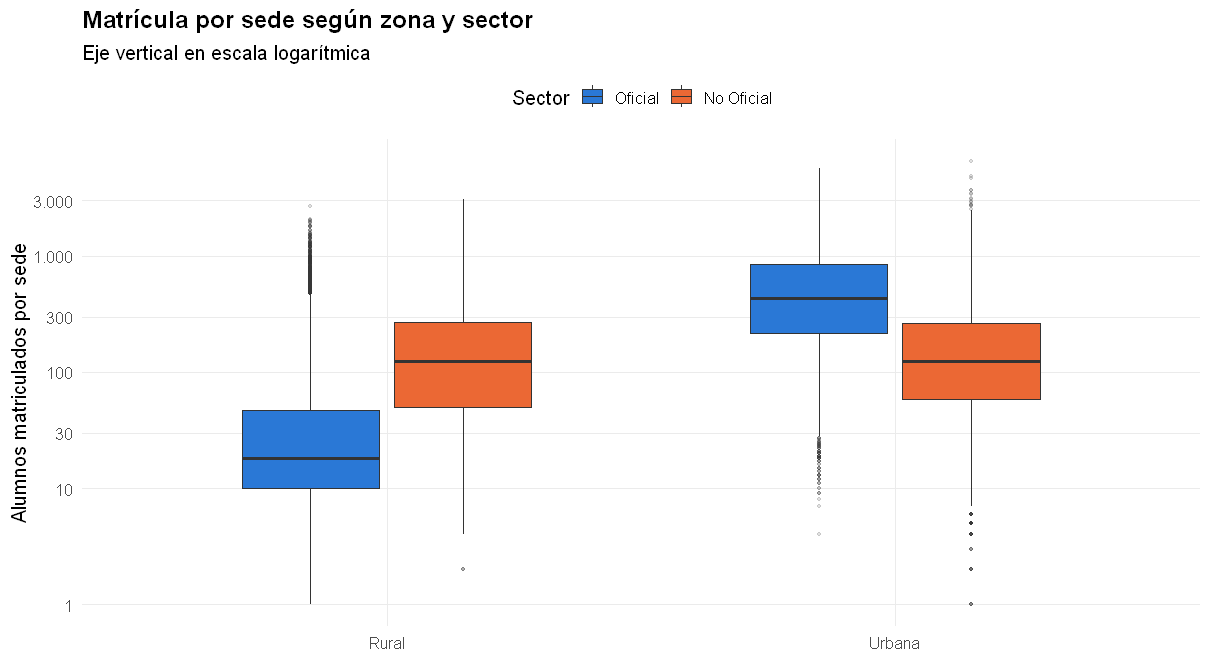

In [16]:
options(repr.plot.width = 11, repr.plot.height = 6)

ggplot(sedes, aes(x = zona, y = matricula_total, fill = sector)) +
  geom_boxplot(outlier.alpha = 0.15, outlier.size = 0.8, width = 0.6) +
  scale_y_log10(labels = miles, breaks = c(1, 10, 30, 100, 300, 1000, 3000)) +
  scale_fill_manual(values = c("Oficial" = azul, "No Oficial" = naranja)) +
  labs(title = "Matrícula por sede según zona y sector",
       subtitle = "Eje vertical en escala logarítmica",
       x = NULL, y = "Alumnos matriculados por sede", fill = "Sector")

mostrar(sedes %>% group_by(zona, sector) %>%
  summarise(sedes = n(), mediana = median(matricula_total), q1 = quantile(matricula_total, 0.25),
            q3 = quantile(matricula_total, 0.75), media = mean(matricula_total)), 1)

**Análisis.** Las sedes oficiales rurales tienen la caja más baja (mediana 18 y la mitad entre 10 y 47 alumnos), y sus atípicos altos son colegios rurales grandes. En la zona urbana la relación se invierte: las oficiales urbanas son las más grandes (mediana 435, con la mitad entre 217 y 852 alumnos), mientras que las no oficiales tienen una mediana cercana a 125 tanto en la zona urbana como en la rural. Por eso la mediana general de las oficiales (27) es baja: no porque las sedes públicas sean pequeñas en sí, sino porque la mayoría son rurales.

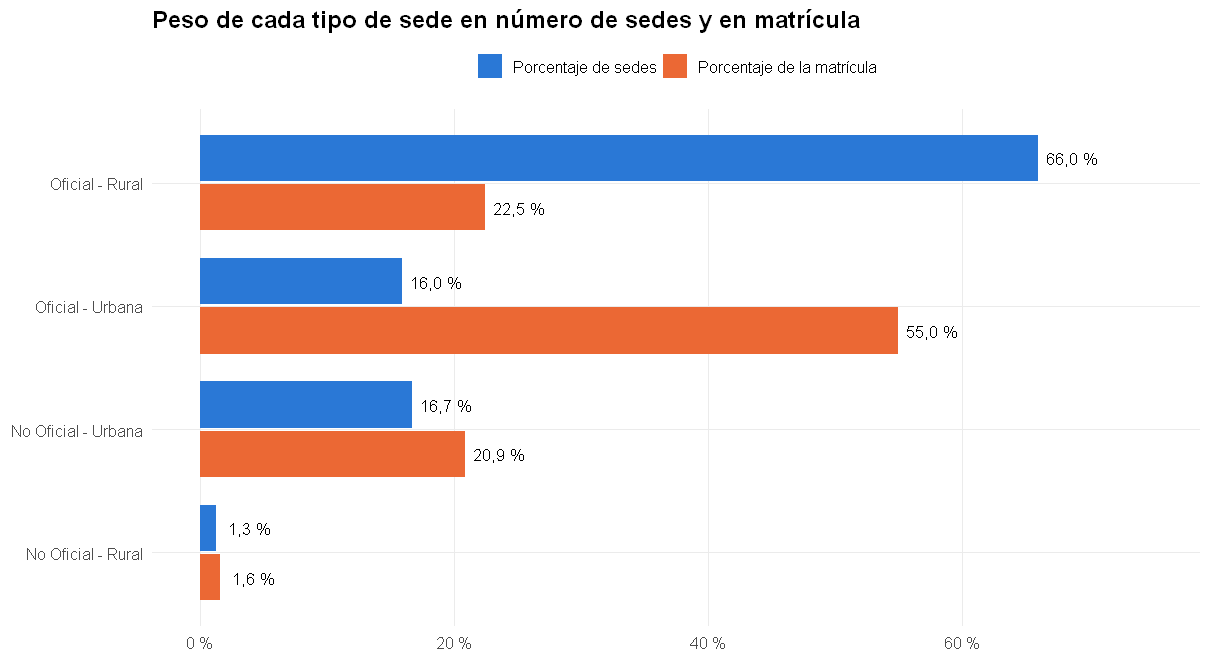

In [17]:
participacion <- sedes %>%
  mutate(grupo = paste(sector, zona, sep = " - ")) %>%
  group_by(grupo) %>%
  summarise(sedes = n(), matricula = sum(matricula_total)) %>%
  mutate(`Porcentaje de sedes` = sedes / sum(sedes) * 100,
         `Porcentaje de la matrícula` = matricula / sum(matricula) * 100)

participacion_larga <- participacion %>%
  pivot_longer(c(`Porcentaje de sedes`, `Porcentaje de la matrícula`),
               names_to = "medida", values_to = "porcentaje") %>%
  mutate(medida = factor(medida, levels = c("Porcentaje de la matrícula", "Porcentaje de sedes")),
         grupo = reorder(grupo, porcentaje))

ggplot(participacion_larga, aes(x = porcentaje, y = grupo, fill = medida)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  geom_text(aes(label = paste0(format(round(porcentaje, 1), decimal.mark = ","), " %")),
            position = position_dodge(width = 0.8), hjust = -0.15, size = 3.8) +
  scale_fill_manual(values = c("Porcentaje de sedes" = azul, "Porcentaje de la matrícula" = naranja)) +
  guides(fill = guide_legend(reverse = TRUE)) +
  scale_x_continuous(limits = c(0, 75), labels = function(v) paste0(v, " %")) +
  labs(title = "Peso de cada tipo de sede en número de sedes y en matrícula",
       x = NULL, y = NULL, fill = NULL)

**Análisis.** Las sedes oficiales rurales son el 66,0 % de todas las sedes, pero reciben solo el 22,5 % de los estudiantes. Con las oficiales urbanas ocurre lo contrario: son el 16,0 % de las sedes y atienden el 55,0 % de la matrícula. Las no oficiales urbanas tienen un peso parecido en sedes (16,7 %) y en matrícula (20,9 %), y las no oficiales rurales son marginales (1,3 % y 1,6 %). La mayor parte de la infraestructura está en el campo, pero la mayor parte de los estudiantes está en las ciudades.

nivel,Oficial,No Oficial,total,porc_no_oficial
Preescolar,565.086,317.801,882.887,"36,0"
Básica primaria,3.136.592,796.272,3.932.864,"20,2"
Básica secundaria,2.376.758,524.621,2.901.379,"18,1"
Media,890.069,224.136,1.114.205,"20,1"
CLEI (adultos),286.404,210.926,497.330,"42,4"


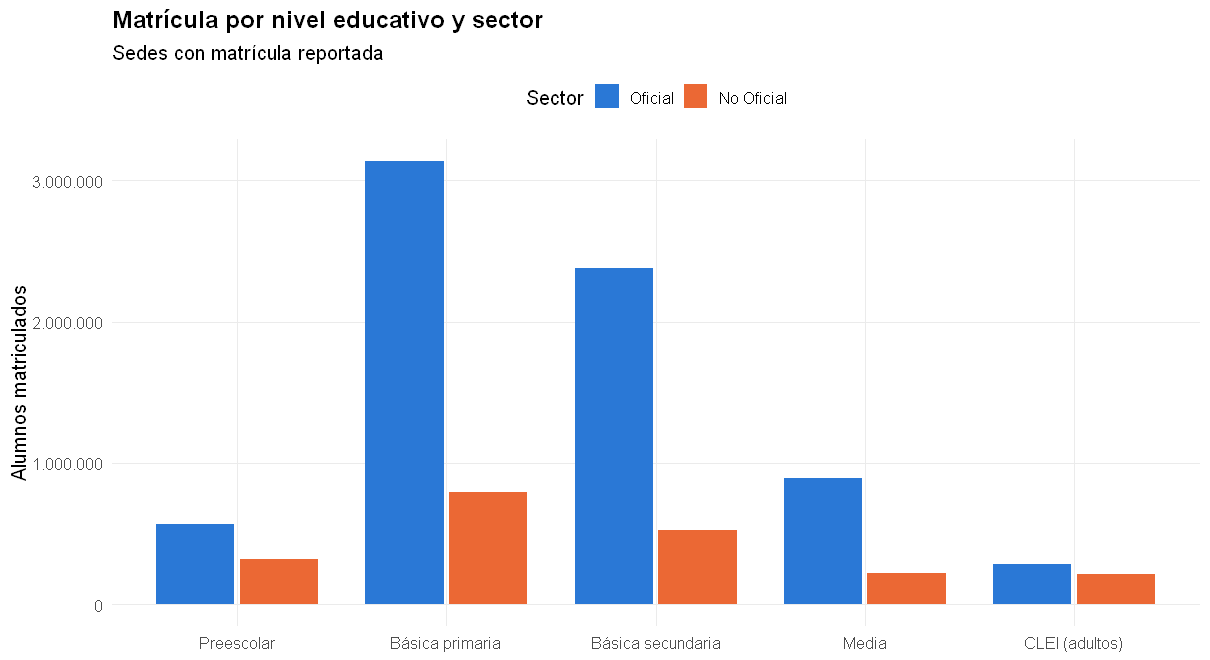

In [18]:
niveles <- matricula %>%
  inner_join(sedes %>% select(sede_codigo, sector), by = c("SEDE_CODIGO" = "sede_codigo")) %>%
  mutate(nivel = recode(NIVELENSE_NOMBRE,
                        "CLEI (Ciclos lectivos integrados - decreto 3011 de 1997)" = "CLEI (adultos)"),
         nivel = factor(nivel, levels = c("Preescolar", "Básica primaria", "Básica secundaria",
                                          "Media", "CLEI (adultos)"))) %>%
  group_by(nivel, sector) %>%
  summarise(alumnos = sum(SEDEALUM_CANTIDAD))

ggplot(niveles, aes(x = nivel, y = alumnos, fill = sector)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  scale_fill_manual(values = c("Oficial" = azul, "No Oficial" = naranja)) +
  scale_y_continuous(labels = miles) +
  labs(title = "Matrícula por nivel educativo y sector",
       subtitle = "Sedes con matrícula reportada",
       x = NULL, y = "Alumnos matriculados", fill = "Sector")

mostrar(niveles %>% pivot_wider(names_from = sector, values_from = alumnos) %>%
  mutate(total = Oficial + `No Oficial`, porc_no_oficial = `No Oficial` / total * 100), 1)

**Análisis.** Básica primaria es el nivel con más estudiantes (3,93 millones), seguido de básica secundaria (2,90 millones), media (1,11 millones), preescolar (0,88 millones) y CLEI (0,50 millones). El sector oficial atiende cerca del 80 % en primaria, secundaria y media, mientras que el no oficial pesa más en preescolar (36,0 %) y en CLEI para adultos (42,4 %), niveles con menor oferta pública. Como primaria tiene 5 grados, secundaria 4 y media 2, el promedio por grado pasa de unos 787.000 alumnos en primaria a 725.000 en secundaria y 557.000 en media, lo que refleja la pérdida de estudiantes a lo largo de la trayectoria escolar.

### 5.3 Top 10 de municipios y departamentos

La métrica usada es la **matrícula total**, es decir, la suma de alumnos de todas las sedes del territorio. Se acompaña con el número de sedes, el promedio de alumnos por sede y el porcentaje de la matrícula nacional.

In [19]:
total_nacional <- sum(sedes$matricula_total)

top_municipios <- sedes %>%
  group_by(cod_muni, municipio, departamento) %>%
  summarise(sedes = n(), matricula = sum(matricula_total)) %>%
  ungroup() %>%
  mutate(promedio_sede = matricula / sedes, porc_nacional = matricula / total_nacional * 100) %>%
  arrange(desc(matricula)) %>%
  slice_head(n = 10) %>%
  mutate(porc_acumulado = cumsum(porc_nacional))

mostrar(top_municipios, 1)

cod_muni,municipio,departamento,sedes,matricula,promedio_sede,porc_nacional,porc_acumulado
11001,"Bogotá, D.C.","Bogotá, D.C.",2.199,1.159.443,"527,3","12,2","12,2"
05001,Medellín,Antioquia,733,402.566,"549,2","4,3","16,5"
76001,Cali,Valle del Cauca,924,335.781,"363,4","3,5","20,0"
08001,Barranquilla,Atlántico,576,261.851,"454,6","2,8","22,8"
13001,Cartagena de Indias,Bolívar,488,242.487,"496,9","2,6","25,4"
08758,Soledad,Atlántico,405,152.962,"377,7","1,6","27,0"
54001,Cúcuta,Norte de Santander,416,152.243,"366,0","1,6","28,6"
47001,Santa Marta,Magdalena,415,131.809,"317,6","1,4","30,0"
25754,Soacha,Cundinamarca,255,128.839,"505,3","1,4","31,3"
20001,Valledupar,Cesar,398,119.812,"301,0","1,3","32,6"


**Análisis.** Bogotá concentra 1.159.443 alumnos, el 12,2 % de la matrícula nacional y casi tres veces la de Medellín (4,3 %). Le siguen Cali, Barranquilla y Cartagena. Los 10 municipios suman el 32,6 % de los estudiantes del país, aunque son menos del 1 % de los 1.120 municipios. Soledad y Soacha entran en la lista como municipios vecinos de Barranquilla y Bogotá, y Soacha tiene uno de los promedios más altos de alumnos por sede (505,3).

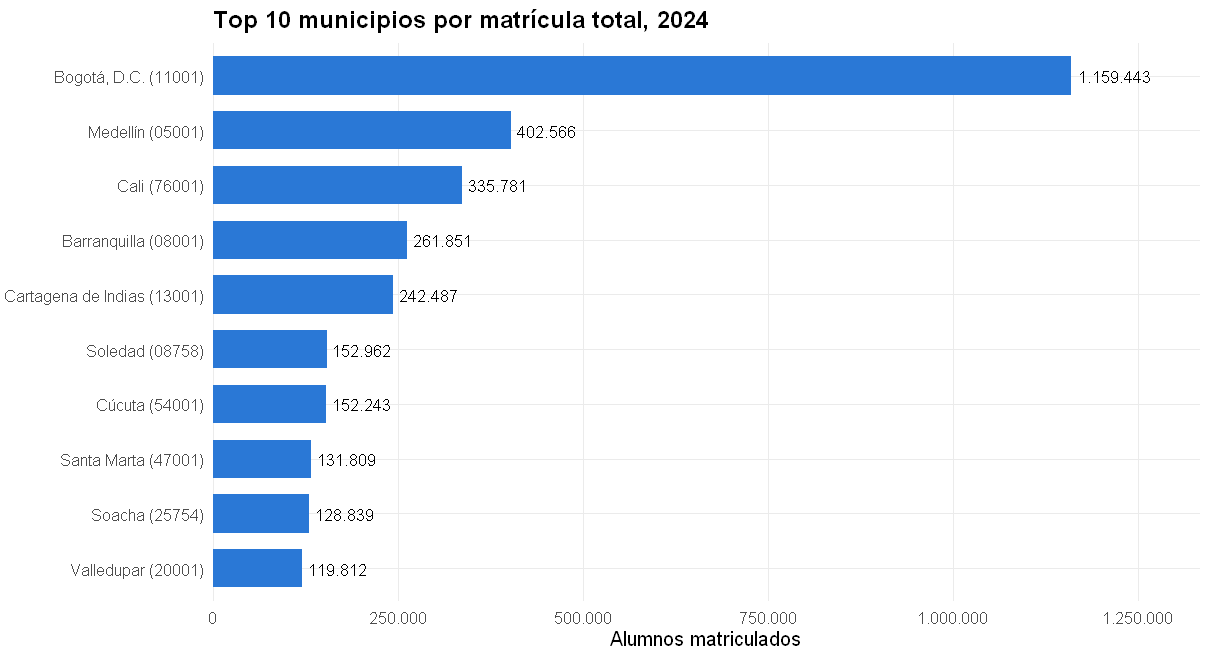

In [20]:
ggplot(top_municipios, aes(x = matricula, y = reorder(paste0(municipio, " (", cod_muni, ")"), matricula))) +
  geom_col(fill = azul, width = 0.7) +
  geom_text(aes(label = miles(matricula)), hjust = -0.1, size = 3.8) +
  scale_x_continuous(labels = miles, expand = expansion(mult = c(0, 0.15))) +
  labs(title = "Top 10 municipios por matrícula total, 2024",
       x = "Alumnos matriculados", y = NULL)

**Análisis.** El gráfico muestra la distancia entre Bogotá y el resto: su barra es casi tres veces la de Medellín y casi diez veces la de Valledupar, que cierra la lista con 119.812 alumnos. Después de las cinco ciudades más grandes la matrícula baja de forma gradual, y los municipios del sexto al décimo lugar tienen entre 119.812 y 152.962 alumnos.

cod_depto,departamento,sedes,municipios,matricula,porc_rural,promedio_sede,porc_nacional,porc_acumulado
11,"Bogotá, D.C.",2.199,1,1.159.443,"2,5","527,3","12,2","12,2"
05,Antioquia,5.832,125,1.148.596,"72,3","196,9","12,1","24,4"
76,Valle del Cauca,3.154,42,710.675,"43,4","225,3","7,5","31,9"
25,Cundinamarca,3.569,116,604.485,"64,9","169,4","6,4","38,3"
08,Atlántico,1.397,23,577.624,"7,3","413,5","6,1","44,4"
13,Bolívar,1.964,46,522.645,"55,5","266,1","5,5","49,9"
68,Santander,3.170,87,419.501,"73,2","132,3","4,4","54,3"
23,Córdoba,2.067,30,375.465,"77,9","181,6","4,0","58,3"
47,Magdalena,1.517,30,367.802,"55,9","242,5","3,9","62,2"
54,Norte de Santander,2.417,40,324.297,"74,1","134,2","3,4","65,6"


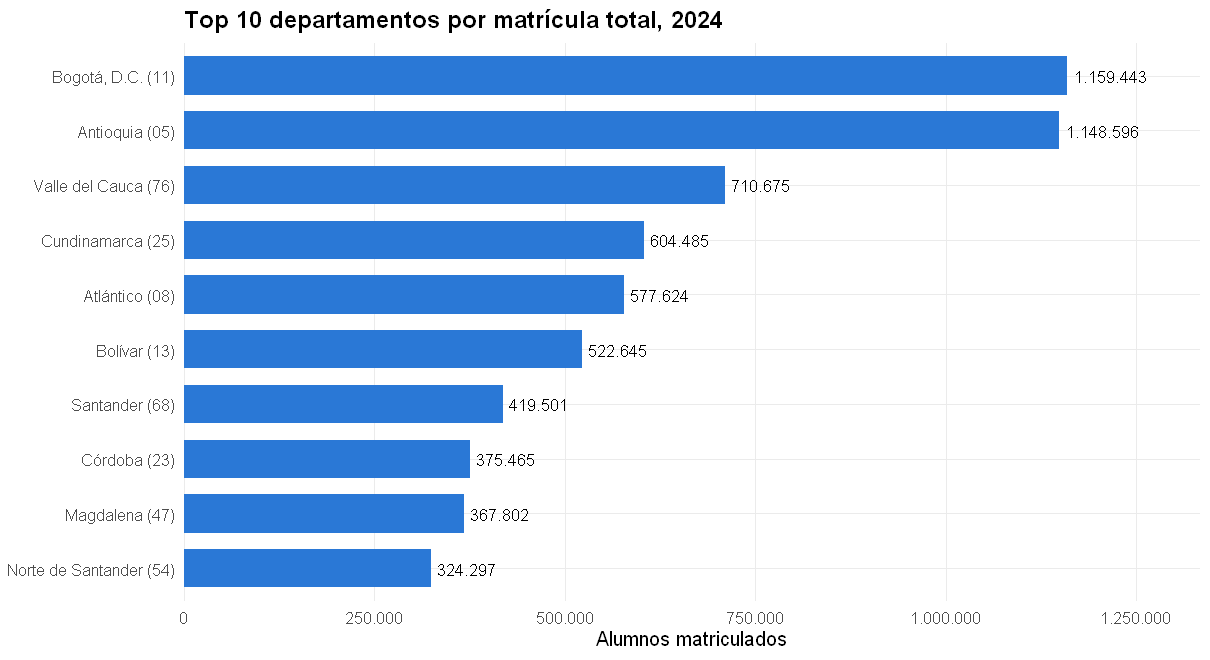

In [21]:
top_departamentos <- sedes %>%
  group_by(cod_depto, departamento) %>%
  summarise(sedes = n(), municipios = n_distinct(cod_muni), matricula = sum(matricula_total),
            porc_rural = mean(zona == "Rural") * 100) %>%
  ungroup() %>%
  mutate(promedio_sede = matricula / sedes, porc_nacional = matricula / total_nacional * 100) %>%
  arrange(desc(matricula)) %>%
  slice_head(n = 10) %>%
  mutate(porc_acumulado = cumsum(porc_nacional))

mostrar(top_departamentos, 1)

ggplot(top_departamentos, aes(x = matricula, y = reorder(paste0(departamento, " (", cod_depto, ")"), matricula))) +
  geom_col(fill = azul, width = 0.7) +
  geom_text(aes(label = miles(matricula)), hjust = -0.1, size = 3.8) +
  scale_x_continuous(labels = miles, expand = expansion(mult = c(0, 0.15))) +
  labs(title = "Top 10 departamentos por matrícula total, 2024",
       x = "Alumnos matriculados", y = NULL)

**Análisis.** Bogotá (12,2 %) y Antioquia (12,1 %) tienen casi la misma matrícula, pero con estructuras opuestas: Bogotá la atiende en 2.199 sedes, solo 2,5 % rurales, con 527 alumnos por sede, mientras que Antioquia necesita 5.832 sedes en 125 municipios, el 72,3 % rurales, con 197 alumnos por sede. Los 10 departamentos concentran el 65,6 % de la matrícula nacional. El promedio por sede sigue a la proporción de sedes rurales: Atlántico, con solo 7,3 % de sedes rurales, tiene 413,5 alumnos por sede, mientras que Santander y Norte de Santander, con más del 73 % de sedes rurales, tienen los promedios más bajos de la lista (132,3 y 134,2).

Boyacá: 2426 sedes, 123 municipios, 238.503 alumnos


cod_muni,municipio,sedes,matricula,porc_oficial,porc_departamento,sede_uptc
15001,Tunja,175,40.286,"30,3","16,9",Con sede UPTC
15759,Sogamoso,102,29.731,"52,0","12,5",Con sede UPTC
15238,Duitama,78,23.886,"38,5","10,0",Con sede UPTC
15176,Chiquinquirá,58,12.079,"63,8","5,1",Con sede UPTC
15572,Puerto Boyacá,50,9.808,"92,0","4,1",Sin sede UPTC
15516,Paipa,46,6.928,"80,4","2,9",Sin sede UPTC
15646,Samacá,29,5.275,"82,8","2,2",Sin sede UPTC
15469,Moniquirá,43,3.926,"90,7","1,6",Sin sede UPTC
15204,Cómbita,24,3.617,"87,5","1,5",Sin sede UPTC
15491,Nobsa,16,3.464,"56,2","1,5",Sin sede UPTC


Matrícula de Boyacá en los 4 municipios con sede UPTC: 44,4 %


Peso de Boyacá en la matrícula nacional: 2,52 %


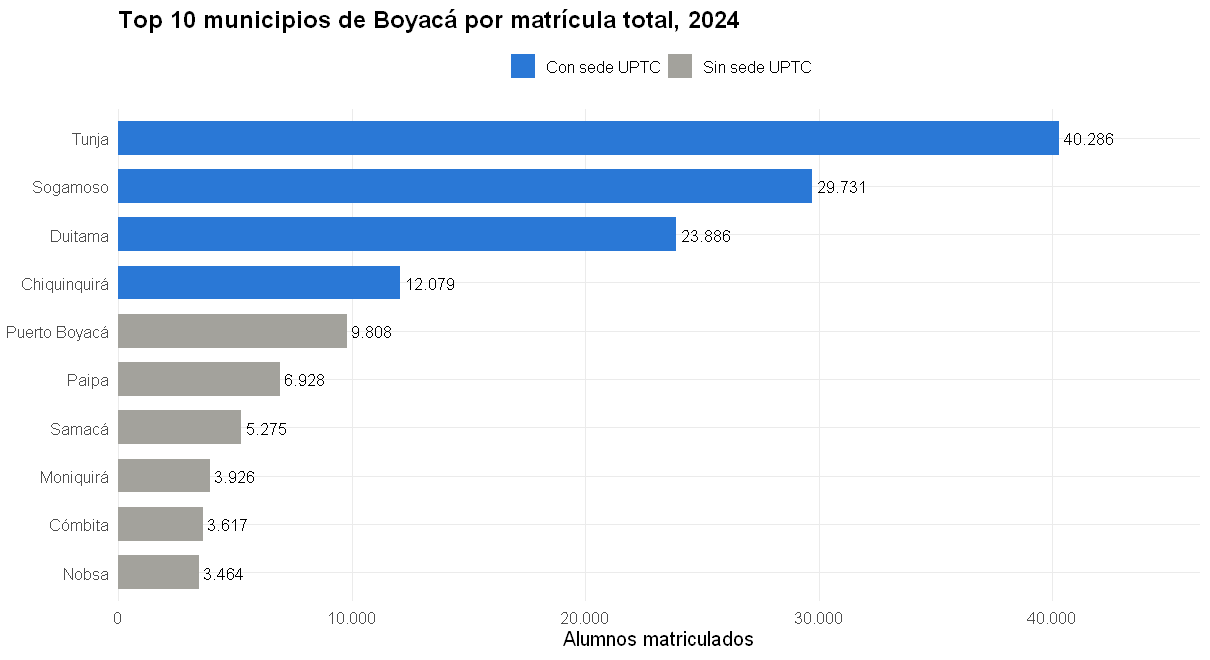

In [22]:
municipios_uptc <- c("Tunja", "Duitama", "Sogamoso", "Chiquinquirá")
boyaca <- sedes %>% filter(departamento == "Boyacá")

top_boyaca <- boyaca %>%
  group_by(cod_muni, municipio) %>%
  summarise(sedes = n(), matricula = sum(matricula_total),
            porc_oficial = mean(sector == "Oficial") * 100) %>%
  ungroup() %>%
  mutate(porc_departamento = matricula / sum(boyaca$matricula_total) * 100) %>%
  arrange(desc(matricula)) %>%
  slice_head(n = 10) %>%
  mutate(sede_uptc = ifelse(municipio %in% municipios_uptc, "Con sede UPTC", "Sin sede UPTC"))

cat("Boyacá:", nrow(boyaca), "sedes,", n_distinct(boyaca$cod_muni), "municipios,",
    format(sum(boyaca$matricula_total), big.mark = ".", decimal.mark = ","), "alumnos\n")
mostrar(top_boyaca, 1)

peso_uptc <- sum(boyaca$matricula_total[boyaca$municipio %in% municipios_uptc]) / sum(boyaca$matricula_total) * 100
cat("Matrícula de Boyacá en los 4 municipios con sede UPTC:", porc(peso_uptc), "%\n")
cat("Peso de Boyacá en la matrícula nacional:", porc(sum(boyaca$matricula_total) / total_nacional * 100, 2), "%\n")

ggplot(top_boyaca, aes(x = matricula, y = reorder(municipio, matricula), fill = sede_uptc)) +
  geom_col(width = 0.7) +
  geom_text(aes(label = miles(matricula)), hjust = -0.1, size = 3.8) +
  scale_fill_manual(values = c("Con sede UPTC" = azul, "Sin sede UPTC" = gris)) +
  scale_x_continuous(labels = miles, expand = expansion(mult = c(0, 0.15))) +
  labs(title = "Top 10 municipios de Boyacá por matrícula total, 2024",
       x = "Alumnos matriculados", y = NULL, fill = NULL)

**Análisis.** Boyacá tiene 2.426 sedes en 123 municipios y 238.503 alumnos (2,52 % del país). Los cuatro primeros lugares son exactamente los municipios donde la UPTC tiene sede: Tunja (40.286 alumnos, 16,9 % del departamento), Sogamoso, Duitama y Chiquinquirá, que juntos concentran el 44,4 % de la matrícula de Boyacá. Después hay una caída fuerte: Puerto Boyacá, en quinto lugar, tiene menos de 10.000 alumnos y desde el sexto ningún municipio supera los 7.000. En Tunja solo el 30,3 % de las sedes son oficiales, lo que muestra una oferta privada amplia en la capital, mientras que en la mayoría de los municipios más pequeños de la lista más del 80 % de las sedes son oficiales (Nobsa es la excepción, con 56,2 %).

## 6. Conclusiones

1. **Limpieza.** De 55.748 sedes se llegó a una base de 53.408 sin nulos ni duplicados: se eliminaron 102 sedes marcadas como duplicadas por el DANE y 3 duplicados por contenido, se excluyeron 2.235 sedes que no funcionaron en 2024 y se imputaron 1.404 sedes activas sin reporte con la mediana de sedes comparables. Lo imputado es solo el 1,49 % de la matrícula final, así que no altera los resultados.
2. **Distribución.** La matrícula por sede es muy asimétrica (media 177, mediana 39, moda 10 y asimetría 4,05). La sede típica en Colombia es pequeña y unas pocas sedes muy grandes elevan el promedio, por lo que la mediana es la medida adecuada para describirla.
3. **Sector y zona.** La zona explica más diferencias que el sector. Las sedes oficiales rurales son dos de cada tres sedes del país, pero atienden menos de una cuarta parte de los estudiantes; las oficiales urbanas son las más grandes (mediana 435 alumnos) y concentran el 55,0 % de la matrícula.
4. **Territorio.** La matrícula está muy concentrada: Bogotá tiene el 12,2 % del país, los 10 municipios con más alumnos suman el 32,6 % y los 10 primeros departamentos el 65,6 %.
5. **Boyacá.** Los cuatro municipios con sede de la UPTC (Tunja, Sogamoso, Duitama y Chiquinquirá) son los cuatro con mayor matrícula del departamento y reúnen el 44,4 % de sus estudiantes, es decir, la universidad está ubicada donde se concentra la demanda educativa de la región.
6. **Limitaciones y siguientes pasos.** El análisis usa la matrícula total y no distingue jornadas ni modelos educativos. Un siguiente paso sería cruzarla con las tablas de docentes e infraestructura de la misma operación para medir alumnos por docente y brechas entre zonas.

## 7. Exportación a HTML

La siguiente celda convierte este notebook en un archivo HTML con el código, las tablas y los gráficos. Guardar el notebook antes de ejecutarla. Usa `jupyter nbconvert` si está disponible y, si no, `python -m nbconvert`.

In [23]:
archivo_nb <- "Tarea_1_EDA_Educacion_Formal_DANE.ipynb"
opciones <- c("--to", "html", "--HTMLExporter.exclude_anchor_links=True", archivo_nb)

if (nzchar(Sys.which("jupyter"))) {
  salida <- system2("jupyter", c("nbconvert", opciones), stdout = TRUE, stderr = TRUE)
} else {
  salida <- system2("python", c("-m", "nbconvert", opciones), stdout = TRUE, stderr = TRUE)
}
cat(salida, sep = "\n")

[NbConvertApp] Converting notebook Tarea_1_EDA_Educacion_Formal_DANE.ipynb to html
[NbConvertApp] Writing 450265 bytes to Tarea_1_EDA_Educacion_Formal_DANE.html
